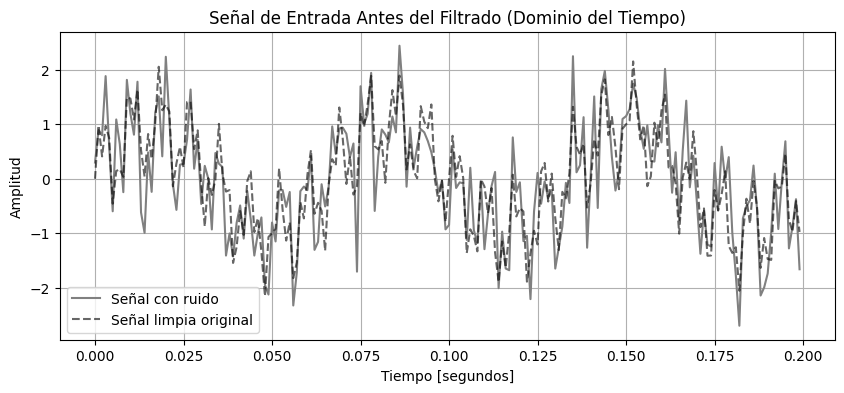

In [5]:
import matplotlib.pyplot as plt
import numpy as np
from scipy import signal

# 1. Configuración del tiempo
fs = 1000.0  # Frecuencia de muestreo: 1000 muestras por segundo (Hz)
t = np.linspace(0, 1.0, int(fs), endpoint=False)  # Duración de 1 segundo

# 2. Creación de la señal compuesta (3 frecuencias distintas: 15 Hz, 120 Hz y 350 Hz)
senal_limpia = (
    1.0 * np.sin(2 * np.pi * 15 * t)
    + 0.7 * np.sin(2 * np.pi * 120 * t)
    + 0.5 * np.sin(2 * np.pi * 350 * t)
)

# 3. Generación de ruido blanco y suma a la señal
np.random.seed(42)  # Semilla para que el ruido sea siempre el mismo
ruido_blanco = 0.6 * np.random.normal(0, 1, len(t))
senal_entrada = senal_limpia + ruido_blanco

# 4. Gráfica en el Dominio del Tiempo (primeros 0.2 segundos para apreciarla bien)
plt.figure(figsize=(10, 4))
plt.plot(t[:200], senal_entrada[:200], color='gray', label='Señal con ruido')
plt.plot(
    t[:200],
    senal_limpia[:200],
    color='black',
    linestyle='--',
    alpha=0.6,
    label='Señal limpia original',
)
plt.title('Señal de Entrada Antes del Filtrado (Dominio del Tiempo)')
plt.xlabel('Tiempo [segundos]')
plt.ylabel('Amplitud')
plt.legend()
plt.grid(True)
plt.show()


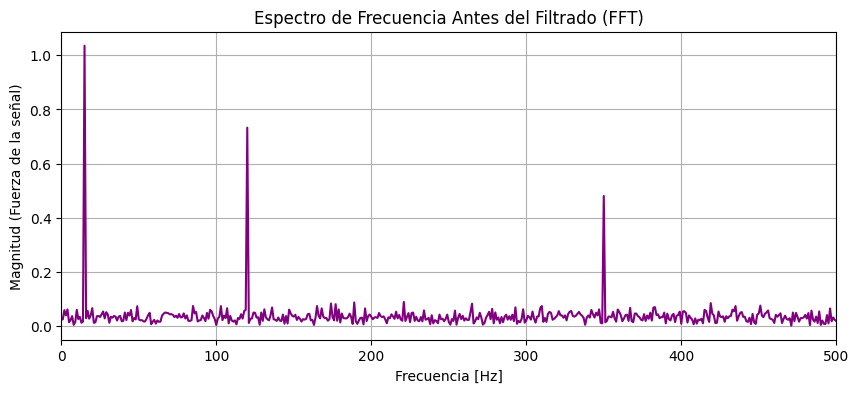

In [6]:
# 1. Función para calcular el espectro de frecuencia (FFT)
def obtener_espectro(senal, fs):
  n = len(senal)
  frecuencias = np.fft.rfftfreq(n, d=1 / fs)
  magnitud = np.abs(np.fft.rfft(senal)) / n * 2
  return frecuencias, magnitud


# 2. Calculamos el espectro de nuestra señal con ruido
freqs_antes, mag_antes = obtener_espectro(senal_entrada, fs)

# 3. Graficamos el espectro antes de filtrar
plt.figure(figsize=(10, 4))
plt.plot(freqs_antes, mag_antes, color='purple')
plt.title('Espectro de Frecuencia Antes del Filtrado (FFT)')
plt.xlabel('Frecuencia [Hz]')
plt.ylabel('Magnitud (Fuerza de la señal)')
plt.xlim(0, 500)
plt.grid(True)
plt.show()


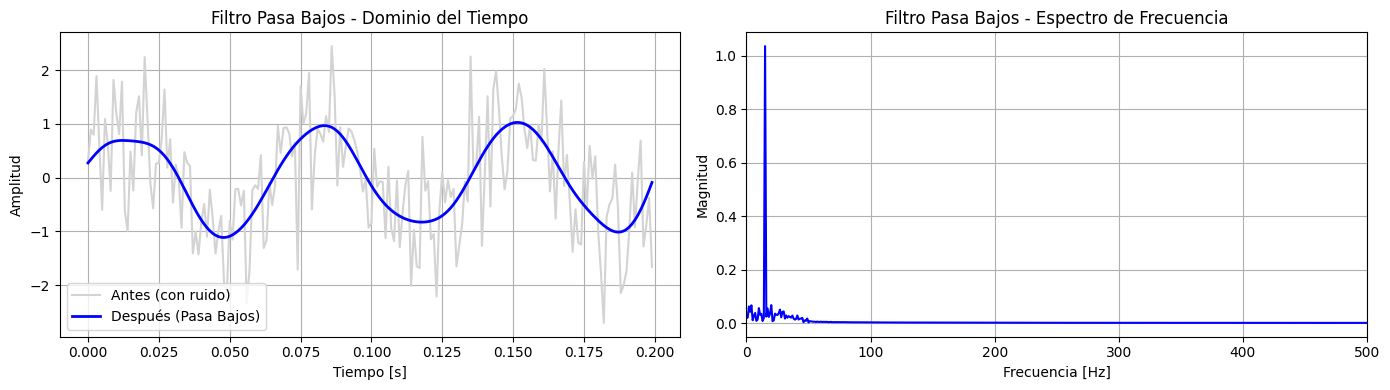

In [9]:
# 1. Diseño del Filtro Pasa Bajos (IIR Butterworth de orden 4, corte en 40 Hz)
sos_pb = signal.butter(N=4, Wn=40, btype='low', fs=fs, output='sos')

# 2. Aplicación del filtro a la señal con ruido (sin desfase temporal)
senal_pasa_bajos = signal.sosfiltfilt(sos_pb, senal_entrada)

# 3. Calculamos el espectro de frecuencia de la señal ya filtrada
freqs_pb, mag_pb = obtener_espectro(senal_pasa_bajos, fs)

# 4. Gráficas comparativas (Tiempo a la izquierda, Frecuencia a la derecha)
fig, axs = plt.subplots(1, 2, figsize=(14, 4))

# Gráfica en el tiempo
axs[0].plot(
    t[:200], senal_entrada[:200], color='lightgray', label='Antes (con ruido)'
)
axs[0].plot(
    t[:200],
    senal_pasa_bajos[:200],
    color='blue',
    linewidth=2,
    label='Después (Pasa Bajos)',
)
axs[0].set_title('Filtro Pasa Bajos - Dominio del Tiempo')
axs[0].set_xlabel('Tiempo [s]')
axs[0].set_ylabel('Amplitud')
axs[0].legend()
axs[0].grid(True)

# Gráfica en la frecuencia
axs[1].plot(freqs_pb, mag_pb, color='blue', linewidth=1.5)
axs[1].set_title('Filtro Pasa Bajos - Espectro de Frecuencia')
axs[1].set_xlabel('Frecuencia [Hz]')
axs[1].set_ylabel('Magnitud')
axs[1].set_xlim(0, 500)
axs[1].grid(True)

plt.tight_layout()
plt.show()


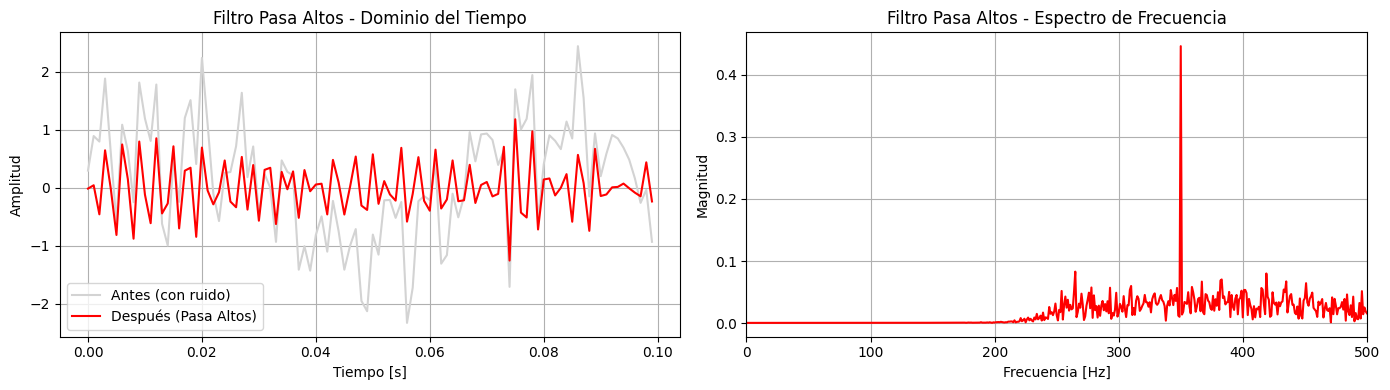

In [13]:
# 1. Diseño del Filtro Pasa Altos (IIR Chebyshev Tipo I, orden 4, corte en 250 Hz)
sos_pa = signal.cheby1(N=4, rp=1, Wn=250, btype='high', fs=fs, output='sos')

# 2. Aplicación del filtro a la señal con ruido
senal_pasa_altos = signal.sosfiltfilt(sos_pa, senal_entrada)

# 3. Calculamos el espectro de frecuencia de la señal ya filtrada
freqs_pa, mag_pa = obtener_espectro(senal_pasa_altos, fs)

# 4. Gráficas comparativas (Tiempo a la izquierda, Frecuencia a la derecha)
fig, axs = plt.subplots(1, 2, figsize=(14, 4))

# Gráfica en el tiempo (mostramos 0.1 segundos para apreciar mejor la onda rápida)
axs[0].plot(
    t[:100], senal_entrada[:100], color='lightgray', label='Antes (con ruido)'
)
axs[0].plot(
    t[:100],
    senal_pasa_altos[:100],
    color='red',
    linewidth=1.5,
    label='Después (Pasa Altos)',
)
axs[0].set_title('Filtro Pasa Altos - Dominio del Tiempo')
axs[0].set_xlabel('Tiempo [s]')
axs[0].set_ylabel('Amplitud')
axs[0].legend()
axs[0].grid(True)

# Gráfica en la frecuencia
axs[1].plot(freqs_pa, mag_pa, color='red', linewidth=1.5)
axs[1].set_title('Filtro Pasa Altos - Espectro de Frecuencia')
axs[1].set_xlabel('Frecuencia [Hz]')
axs[1].set_ylabel('Magnitud')
axs[1].set_xlim(0, 500)
axs[1].grid(True)

plt.tight_layout()
plt.show()


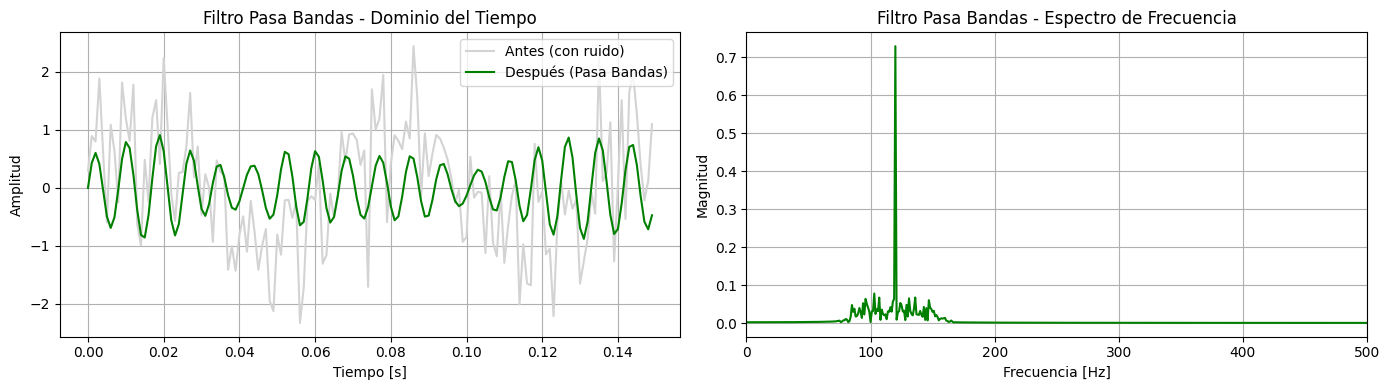

In [14]:
# 1. Diseño del Filtro Pasa Bandas (FIR con ventana Hamming, 101 coeficientes, banda 80-160 Hz)
taps_pbanda = signal.firwin(
    numtaps=101, cutoff=[80, 160], pass_zero=False, window='hamming', fs=fs
)

# 2. Aplicación del filtro FIR a la señal con ruido (sin desfase temporal)
senal_pasa_bandas = signal.filtfilt(taps_pbanda, 1.0, senal_entrada)

# 3. Calculamos el espectro de frecuencia de la señal ya filtrada
freqs_pbanda, mag_pbanda = obtener_espectro(senal_pasa_bandas, fs)

# 4. Gráficas comparativas (Tiempo a la izquierda, Frecuencia a la derecha)
fig, axs = plt.subplots(1, 2, figsize=(14, 4))

# Gráfica en el tiempo (primeros 0.15 segundos)
axs[0].plot(
    t[:150], senal_entrada[:150], color='lightgray', label='Antes (con ruido)'
)
axs[0].plot(
    t[:150],
    senal_pasa_bandas[:150],
    color='green',
    linewidth=1.5,
    label='Después (Pasa Bandas)',
)
axs[0].set_title('Filtro Pasa Bandas - Dominio del Tiempo')
axs[0].set_xlabel('Tiempo [s]')
axs[0].set_ylabel('Amplitud')
axs[0].legend()
axs[0].grid(True)

# Gráfica en la frecuencia
axs[1].plot(freqs_pbanda, mag_pbanda, color='green', linewidth=1.5)
axs[1].set_title('Filtro Pasa Bandas - Espectro de Frecuencia')
axs[1].set_xlabel('Frecuencia [Hz]')
axs[1].set_ylabel('Magnitud')
axs[1].set_xlim(0, 500)
axs[1].grid(True)

plt.tight_layout()
plt.show()


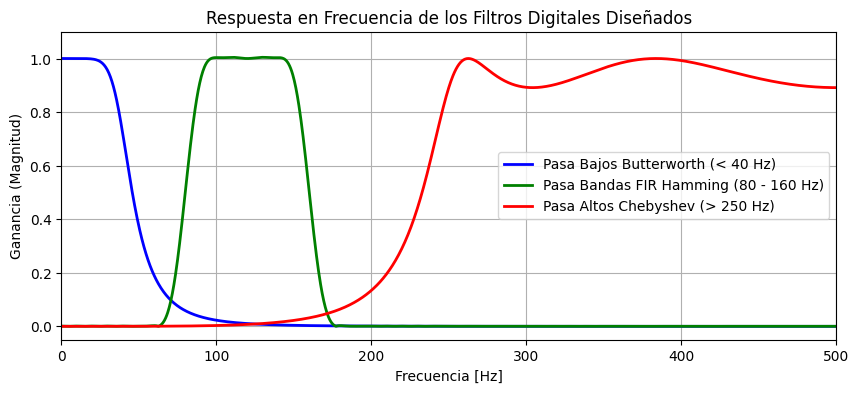

In [16]:
# 1. Calculamos la respuesta en frecuencia de cada filtro diseñado
w_pb, h_pb = signal.sosfreqz(sos_pb, worN=1500, fs=fs)
w_pa, h_pa = signal.sosfreqz(sos_pa, worN=1500, fs=fs)
w_pbanda, h_pbanda = signal.freqz(taps_pbanda, worN=1500, fs=fs)

# 2. Graficamos las tres respuestas en frecuencia juntas
plt.figure(figsize=(10, 4))
plt.plot(
    w_pb,
    np.abs(h_pb),
    color='blue',
    linewidth=2,
    label='Pasa Bajos Butterworth (< 40 Hz)',
)
plt.plot(
    w_pbanda,
    np.abs(h_pbanda),
    color='green',
    linewidth=2,
    label='Pasa Bandas FIR Hamming (80 - 160 Hz)',
)
plt.plot(
    w_pa,
    np.abs(h_pa),
    color='red',
    linewidth=2,
    label='Pasa Altos Chebyshev (> 250 Hz)',
)

plt.title('Respuesta en Frecuencia de los Filtros Digitales Diseñados')
plt.xlabel('Frecuencia [Hz]')
plt.ylabel('Ganancia (Magnitud)')
plt.xlim(0, 500)
plt.ylim(-0.05, 1.1)
plt.legend()
plt.grid(True)
plt.show()
